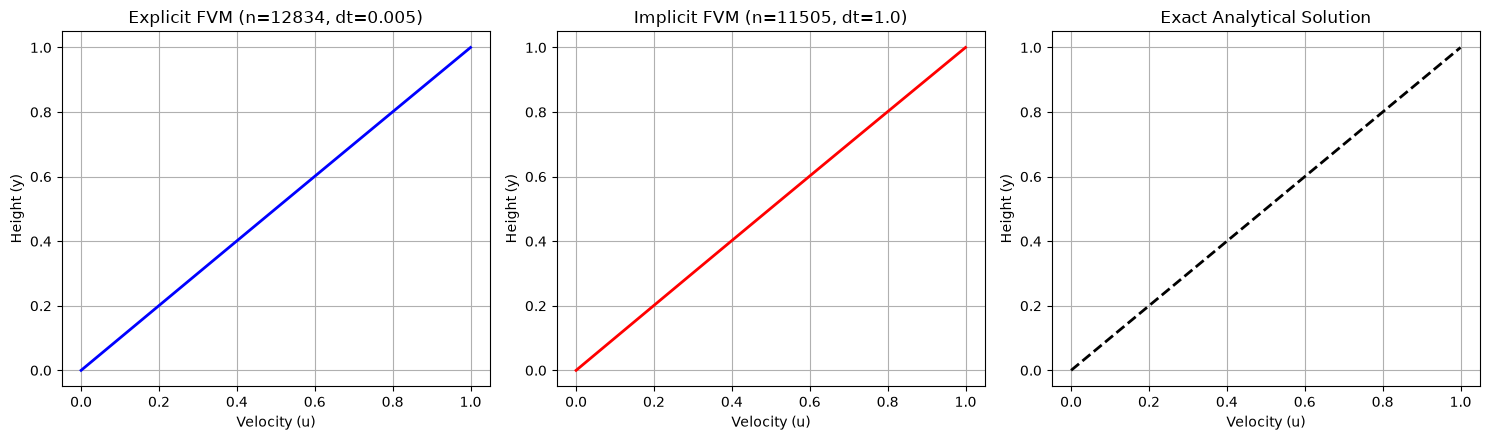

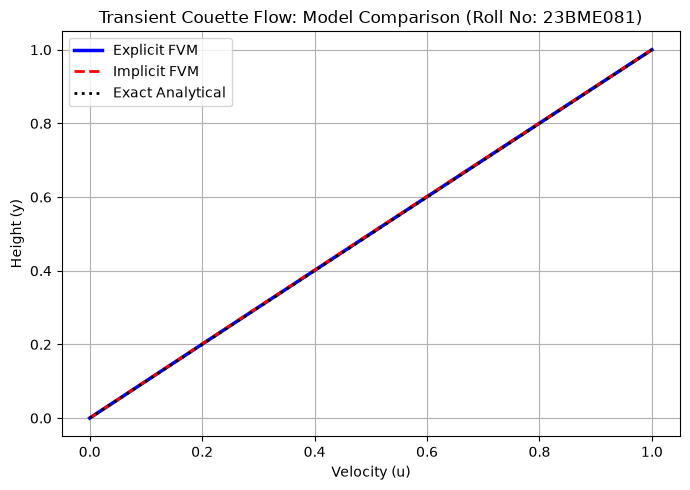

In [2]:
"""
===================================================================
  CFD & HT Lab - Experiment 5
  Topic: Transient Couette Flow (Explicit, Implicit & Analytical)
  
  Student Name : Dev Pateliya
  Roll Number  : 23BME081
  Semester     : 7th Semester (B.Tech Mechanical Engineering)
===================================================================
"""

import numpy as np
import matplotlib.pyplot as plt

ny = 100
H, U_bottom, U_top, T_ref, Re = 1.0, 0.0, 1.0, 1.0, 100.0
dy = H / ny
y_coords = np.linspace(0, H, ny)
nit = 1000000

u_exact = U_bottom + (U_top - U_bottom) * y_coords / H

F = 0.5
dt_exp = F * (dy**2) * Re / (T_ref * U_top)
u_exp = np.zeros(ny)
u_exp[0] = U_bottom
u_exp[-1] = U_top

for n_exp in range(nit):
    u_old = u_exp.copy()
    d2u = (u_old[2:] + u_old[:-2] - 2 * u_old[1:-1]) / (dy**2)
    u_exp[1:-1] = u_old[1:-1] + dt_exp * ((1.0 / Re) * (T_ref * U_top / H) * d2u)
    u_exp[0], u_exp[-1] = U_bottom, U_top
    if np.max(np.abs(u_exp - u_old)) < 1e-6:
        break

u_imp = np.zeros(ny)
u_imp[0] = U_bottom
u_imp[-1] = U_top
dt_imp = 1.0
coeff = (1.0 / Re) * (T_ref * U_top / H)

for n_imp in range(nit):
    u_old = u_imp.copy()
    u_imp[1:-1] = ((coeff / dy) * (u_imp[2:] + u_imp[:-2]) + (dy / dt_imp) * u_old[1:-1]) / ((2.0 * coeff / dy) + (dy / dt_imp))
    u_imp[0], u_imp[-1] = U_bottom, U_top
    if np.max(np.abs(u_imp - u_old)) < 1e-6:
        break

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))

ax[0].plot(u_exp, y_coords, 'b-', linewidth=2)
ax[0].set_xlabel('Velocity (u)')
ax[0].set_ylabel('Height (y)')
ax[0].set_title(f'Explicit FVM (n={n_exp}, dt={dt_exp})')
ax[0].grid(True)

ax[1].plot(u_imp, y_coords, 'r-', linewidth=2)
ax[1].set_xlabel('Velocity (u)')
ax[1].set_ylabel('Height (y)')
ax[1].set_title(f'Implicit FVM (n={n_imp}, dt={dt_imp})')
ax[1].grid(True)

ax[2].plot(u_exact, y_coords, 'k--', linewidth=2)
ax[2].set_xlabel('Velocity (u)')
ax[2].set_ylabel('Height (y)')
ax[2].set_title('Exact Analytical Solution')
ax[2].grid(True)

plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(u_exp, y_coords, 'b-', linewidth=2.5, label='Explicit FVM')
plt.plot(u_imp, y_coords, 'r--', linewidth=2.0, label='Implicit FVM')
plt.plot(u_exact, y_coords, 'k:', linewidth=2.0, label='Exact Analytical')
plt.xlabel('Velocity (u)')
plt.ylabel('Height (y)')
plt.title('Transient Couette Flow: Model Comparison')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()